In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import make_scorer, precision_score, recall_score, f1_score

from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import LinearSVC, SVC
from sklearn.ensemble import RandomForestClassifier

import warnings
warnings.filterwarnings("ignore")

print("All libraries imported successfully!")

All libraries imported successfully!


In [5]:
import pandas as pd

df = pd.read_csv("../Data/clean_data.csv")

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

display(df.head())

Dataset shape: (430, 262)

Column names:
['0', '1', '2', '3', '4', '5', '6', '7', '8', '9', '10', '11', '12', '14', '15', '16', '17', '18', '20', '21', '22', '23', '24', '25', '26', '27', '28', '29', '30', '31', '32', '33', '34', '35', '36', '37', '38', '39', '40', '41', '42', '43', '44', '45', '46', '47', '48', '49', '50', '51', '52', '53', '54', '55', '56', '57', '58', '59', '60', '61', '62', '63', '64', '65', '66', '68', '70', '71', '72', '73', '74', '75', '76', '77', '78', '79', '80', '81', '82', '84', '85', '86', '87', '88', '89', '90', '91', '92', '93', '94', '95', '96', '97', '98', '99', '100', '101', '102', '103', '104', '105', '106', '107', '108', '109', '110', '111', '112', '113', '114', '115', '116', '117', '118', '119', '120', '121', '122', '123', '124', '125', '126', '127', '128', '129', '130', '133', '134', '135', '136', '137', '138', '140', '142', '144', '146', '147', '148', '149', '150', '152', '153', '154', '155', '158', '159', '160', '161', '162', '163', '165', '166',

,0,1,2,3,4,5,6,7,8,9,...,269,270,271,272,273,275,276,277,278,279
0,75,0,190.0,80.0,91,193,371,174,121,-16,...,-0.3,0.0,9.0,-0.9,0.0,0.9,2.9,23.3,49.4,1
1,56,1,165.0,64.0,81,174,401,149,39,25,...,-0.5,0.0,8.5,0.0,0.0,0.2,2.1,20.4,38.8,1
2,54,0,172.0,95.0,138,163,386,185,102,96,...,0.9,0.0,9.5,-2.4,0.0,0.3,3.4,12.3,49.0,1
3,55,0,175.0,94.0,100,202,380,179,143,28,...,0.1,0.0,12.2,-2.2,0.0,0.4,2.6,34.6,61.6,0
4,75,0,190.0,80.0,88,181,360,177,103,-16,...,-0.4,0.0,13.1,-3.6,0.0,-0.1,3.9,25.4,62.8,1


In [6]:
# Check the last 5 column names
print("Last 5 columns:")
print(df.columns[-5:].tolist())

# Check the last column's values
print("\nLast column distribution:")
print(df.iloc[:, -1].value_counts(dropna=False))

# Check missing values
print("\nTotal missing values:")
print(df.isnull().sum().sum())

Last 5 columns:
['275', '276', '277', '278', '279']

Last column distribution:
279
0    245
1    185
Name: count, dtype: int64

Total missing values:
31


In [7]:
# Define the target column
TARGET_COLUMN = "279"

# Separate features and target
X = df.drop(columns=[TARGET_COLUMN])
y = df[TARGET_COLUMN]

# Display shapes
print("Features shape:", X.shape)
print("Target shape:", y.shape)

# Display target distribution
print("\nTarget distribution:")
print(y.value_counts())

# Check missing values in features
print("\nMissing values in features:", X.isnull().sum().sum())

Features shape: (430, 261)
Target shape: (430,)

Target distribution:
279
0    245
1    185
Name: count, dtype: int64

Missing values in features: 31


In [8]:
from sklearn.model_selection import StratifiedKFold

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("Stratified 5-Fold Cross-Validation is ready!")

Stratified 5-Fold Cross-Validation is ready!


In [9]:
from sklearn.metrics import make_scorer
from sklearn.model_selection import cross_validate

scoring = {
    "accuracy": "accuracy",

    "precision": make_scorer(
        precision_score,
        pos_label=1,
        zero_division=0
    ),

    "recall": make_scorer(
        recall_score,
        pos_label=1,
        zero_division=0
    ),

    "f1": make_scorer(
        f1_score,
        pos_label=1,
        zero_division=0
    )
}

print("Evaluation metrics are ready!")

Evaluation metrics are ready!


In [10]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

def evaluate_model(model, X, y):

    pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", model)
    ])

    scores = cross_validate(
        pipeline,
        X,
        y,
        cv=cv,
        scoring=scoring,
        return_train_score=False,
        n_jobs=-1
    )

    return {
        "Accuracy": scores["test_accuracy"].mean(),
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1-score": scores["test_f1"].mean()
    }

print("Shared evaluation function created!")

Shared evaluation function created!


In [11]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import LinearSVC, SVC
from sklearn.ensemble import RandomForestClassifier

models = {
    "KNN": KNeighborsClassifier(),

    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "Linear SVC": LinearSVC(
        max_iter=10000,
        random_state=42
    ),

    "RBF SVC": SVC(
        kernel="rbf"
    ),

    "Random Forest": RandomForestClassifier(
        random_state=42
    )
}

print("All six baseline models are ready!")

for name in models:
    print(name)

All six baseline models are ready!
KNN
Logistic Regression
Decision Tree
Linear SVC
RBF SVC
Random Forest


In [12]:
results = []

for name, model in models.items():

    print(f"Evaluating {name}...")

    metrics = evaluate_model(model, X, y)

    metrics["Model"] = name

    results.append(metrics)

print("All models evaluated successfully!")

Evaluating KNN...
Evaluating Logistic Regression...
Evaluating Decision Tree...
Evaluating Linear SVC...
Evaluating RBF SVC...
Evaluating Random Forest...
All models evaluated successfully!


In [13]:
results_df = pd.DataFrame(results)

results_df = results_df[
    ["Model", "Accuracy", "Precision", "Recall", "F1-score"]
]

display(results_df.round(4))

,Model,Accuracy,Precision,Recall,F1-score
0,KNN,0.6581,0.7910,0.2757,0.4025
1,Logistic Regression,0.7465,0.7228,0.6703,0.6946
2,Decision Tree,0.7512,0.7403,0.6757,0.7035
3,Linear SVC,0.6953,0.6531,0.6270,0.6396
4,RBF SVC,0.7674,0.7771,0.6486,0.7059
5,Random Forest,0.8442,0.8475,0.7838,0.8126


## Baseline Model Performance Analysis

Six machine learning models were evaluated using stratified 5-fold cross-validation with a fixed random state of 42. All models used the same preprocessing pipeline consisting of median imputation followed by standard scaling.

The Random Forest classifier achieved the best overall performance, with an accuracy of **84.42%**, precision of **84.75%**, recall of **78.38%**, and F1-score of **81.26%**. It outperformed the other five baseline models across all four evaluation metrics.

The RBF-based Support Vector Classifier achieved the second-highest accuracy of 76.74% and an F1-score of 70.59%, indicating comparatively good performance among the remaining models.

KNN achieved a relatively high precision of 79.10% but a considerably lower recall of 27.57%. This suggests that although its positive predictions were often correct, it failed to identify a substantial proportion of actual arrhythmia cases.

Logistic Regression and Decision Tree produced comparable results, while Linear SVC showed comparatively lower performance.

Overall, Random Forest emerged as the strongest baseline model and will be a suitable candidate for further experimentation and hyperparameter tuning in subsequent stages of the project.

In [14]:
results_df.to_csv(
    "baseline_results.csv",
    index=False
)

print("Results CSV saved successfully!")

Results CSV saved successfully!


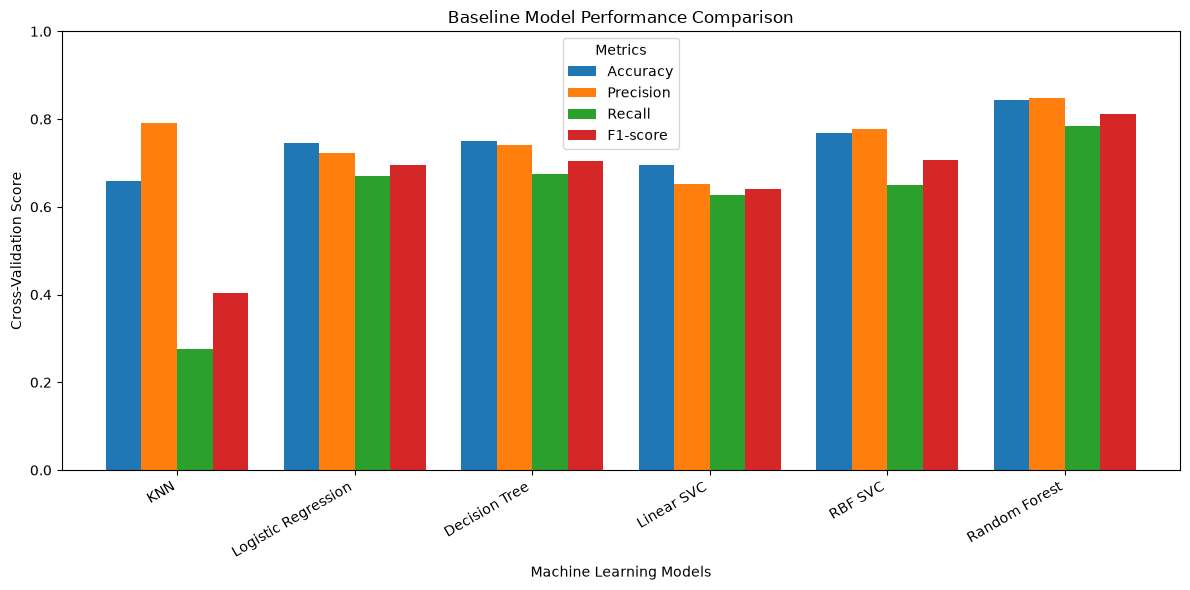

In [15]:
results_plot = results_df.set_index("Model")

results_plot.plot(
    kind="bar",
    figsize=(12, 6),
    ylim=(0, 1),
    width=0.8
)

plt.title("Baseline Model Performance Comparison")
plt.xlabel("Machine Learning Models")
plt.ylabel("Cross-Validation Score")
plt.xticks(rotation=30, ha="right")
plt.legend(title="Metrics")
plt.tight_layout()
plt.show()

In [16]:
from pathlib import Path

output_path = Path("baseline_results.csv")

results_df.to_csv(output_path, index=False)

print("Saved at:", output_path.resolve())

Saved at: /Users/akshitaajasrotia/cardio-classify/model/baseline_results.csv
